# 🌍 Travel Recommendation System
**Data Science Project, IBM 7th Semester**

This notebook cleans a dataset of 35 global destinations, explores it with charts, and builds two recommenders:

1. **Preference-based**: you choose season, budget, safety, crowds and temperature, and it ranks destinations by a weighted match score.
2. **Similarity-based**: "I liked Paris, what else is like it?" using cosine similarity.

A matching web app is provided in `app.py` (run with `streamlit run app.py`).

**Before running:** keep `global_travel_destinations.csv` in the same folder as this notebook, then use **Run All**.

## 1. Import libraries and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.width", 140)

CSV_PATH = Path("global_travel_destinations.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH.resolve()}. Put the CSV in the same folder as this notebook."
    )

raw = pd.read_csv(CSV_PATH)
raw.head()

,destination,country,continent,best_season,avg_temperature_c,avg_rainfall_mm,avg_aqi,crowd_level,safety_rating_5,estimated_daily_budget_usd,popularity_score_100
0,Paris,France,Europe,Spring,16,55,38,High,4.5,180,92
1,Rome,Italy,Europe,Spring,18,62,42,High,4.2,150,90
2,Barcelona,Spain,Europe,Summer,25,35,45,High,4.1,145,89
3,Amsterdam,Netherlands,Europe,Spring,14,68,30,High,4.4,165,87
4,London,United Kingdom,Europe,Summer,19,58,36,High,4.3,190,91


## 2. Understand the data

In [2]:
print("Shape:", raw.shape)
raw.info()

Shape: (35, 11)
<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   destination                 35 non-null     str    
 1   country                     35 non-null     str    
 2   continent                   35 non-null     str    
 3   best_season                 35 non-null     str    
 4   avg_temperature_c           35 non-null     int64  
 5   avg_rainfall_mm             35 non-null     int64  
 6   avg_aqi                     35 non-null     int64  
 7   crowd_level                 35 non-null     str    
 8   safety_rating_5             35 non-null     float64
 9   estimated_daily_budget_usd  35 non-null     int64  
 10  popularity_score_100        35 non-null     int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 4.3 KB


In [3]:
print("Missing values per column:")
print(raw.isnull().sum())
print("\nDuplicate rows:", raw.duplicated().sum())
raw.describe().T.round(2)

Missing values per column:
destination                   0
country                       0
continent                     0
best_season                   0
avg_temperature_c             0
avg_rainfall_mm               0
avg_aqi                       0
crowd_level                   0
safety_rating_5               0
estimated_daily_budget_usd    0
popularity_score_100          0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
avg_temperature_c,35.0,21.31,4.68,13.0,17.50,22.0,25.5,29.0
avg_rainfall_mm,35.0,61.51,47.48,3.0,22.50,55.0,82.5,240.0
avg_aqi,35.0,49.57,27.02,12.0,31.00,44.0,60.0,125.0
safety_rating_5,35.0,4.21,0.38,3.5,3.95,4.2,4.5,4.8
estimated_daily_budget_usd,35.0,126.43,52.24,40.0,77.50,135.0,167.5,230.0
popularity_score_100,35.0,88.14,3.96,80.0,85.50,88.0,91.0,96.0


## 3. Data cleaning
The cleaning function strips whitespace, gives the columns shorter names, converts numeric columns to numbers, removes duplicates and drops incomplete rows.

| Original column | New name |
|---|---|
| avg_temperature_c | temperature |
| avg_rainfall_mm | rainfall |
| avg_aqi | aqi (air quality index, lower is cleaner) |
| safety_rating_5 | safety |
| estimated_daily_budget_usd | budget |
| popularity_score_100 | popularity |

In [4]:
CROWD_MAP = {"Low": 0.0, "Medium": 0.5, "High": 1.0}
TEXT_COLS = ["destination", "country", "continent", "best_season", "crowd_level"]
NUM_COLS = ["temperature", "rainfall", "aqi", "safety", "budget", "popularity"]
COLUMN_RENAMES = {
    "avg_temperature_c": "temperature",
    "avg_rainfall_mm": "rainfall",
    "avg_aqi": "aqi",
    "safety_rating_5": "safety",
    "estimated_daily_budget_usd": "budget",
    "popularity_score_100": "popularity",
}


def clean_data(raw):
    """Standardise column names, fix types, drop duplicates and incomplete rows."""
    df = raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df = df.rename(columns=COLUMN_RENAMES)
    for col in TEXT_COLS:
        df[col] = df[col].astype(str).str.strip()
    for col in NUM_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.drop_duplicates()
    df = df.dropna(subset=TEXT_COLS + NUM_COLS)
    return df.reset_index(drop=True)

In [5]:
clean = clean_data(raw)
print(f"Rows before: {len(raw)} | after cleaning: {len(clean)}")
clean.head()

Rows before: 35 | after cleaning: 35

,destination,country,continent,best_season,temperature,rainfall,aqi,crowd_level,safety,budget,popularity
0,Paris,France,Europe,Spring,16,55,38,High,4.5,180,92
1,Rome,Italy,Europe,Spring,18,62,42,High,4.2,150,90
2,Barcelona,Spain,Europe,Summer,25,35,45,High,4.1,145,89
3,Amsterdam,Netherlands,Europe,Spring,14,68,30,High,4.4,165,87
4,London,United Kingdom,Europe,Summer,19,58,36,High,4.3,190,91


## 4. Feature engineering
We add a numeric **crowd score** (Low 0, Medium 0.5, High 1) and a **budget tier** (Budget up to $80/day, Mid-range up to $150, Premium above).

In [6]:
def add_features(df):
    """Add helper columns used by the recommender and the charts."""
    df = df.copy()
    df["crowd_score"] = df["crowd_level"].map(CROWD_MAP)
    df["budget_tier"] = pd.cut(
        df["budget"], bins=[0, 80, 150, 10_000],
        labels=["Budget", "Mid-range", "Premium"],
    ).astype(str)
    return df


def build_similarity(df):
    """Cosine similarity between destinations using numbers + continent + season."""
    numeric = df[NUM_COLS + ["crowd_score"]]
    scaled = StandardScaler().fit_transform(numeric)
    categories = pd.get_dummies(df[["continent", "best_season"]]).astype(float).to_numpy() * 0.5
    return cosine_similarity(np.hstack([scaled, categories]))

In [7]:
df = add_features(clean)
similarity_matrix = build_similarity(df)
df[["destination", "country", "budget", "budget_tier", "crowd_level", "crowd_score"]].head(8)

,destination,country,budget,budget_tier,crowd_level,crowd_score
0,Paris,France,180,Premium,High,1.0
1,Rome,Italy,150,Mid-range,High,1.0
2,Barcelona,Spain,145,Mid-range,High,1.0
3,Amsterdam,Netherlands,165,Premium,High,1.0
4,London,United Kingdom,190,Premium,High,1.0
5,Zurich,Switzerland,230,Premium,Medium,0.5
6,Santorini,Greece,175,Premium,High,1.0
7,Prague,Czech Republic,110,Mid-range,Medium,0.5


## 5. Exploratory data analysis

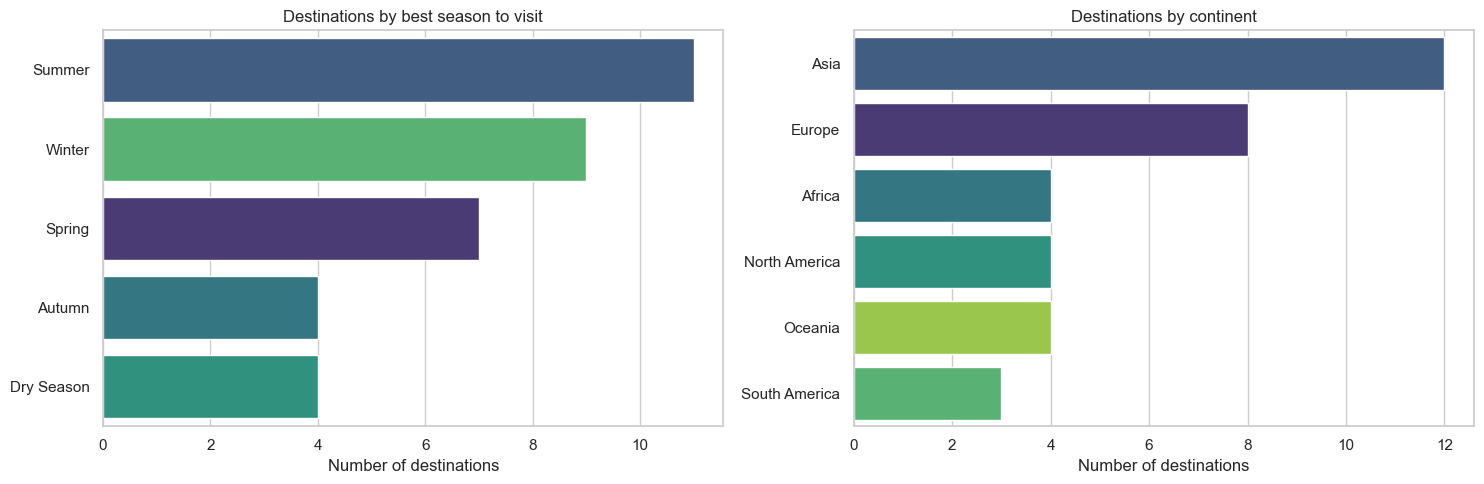

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

season_order = df["best_season"].value_counts().index
sns.countplot(data=df, y="best_season", order=season_order, hue="best_season", legend=False, ax=axes[0])
axes[0].set_title("Destinations by best season to visit")
axes[0].set_xlabel("Number of destinations"); axes[0].set_ylabel("")

cont_order = df["continent"].value_counts().index
sns.countplot(data=df, y="continent", order=cont_order, hue="continent", legend=False, ax=axes[1])
axes[1].set_title("Destinations by continent")
axes[1].set_xlabel("Number of destinations"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

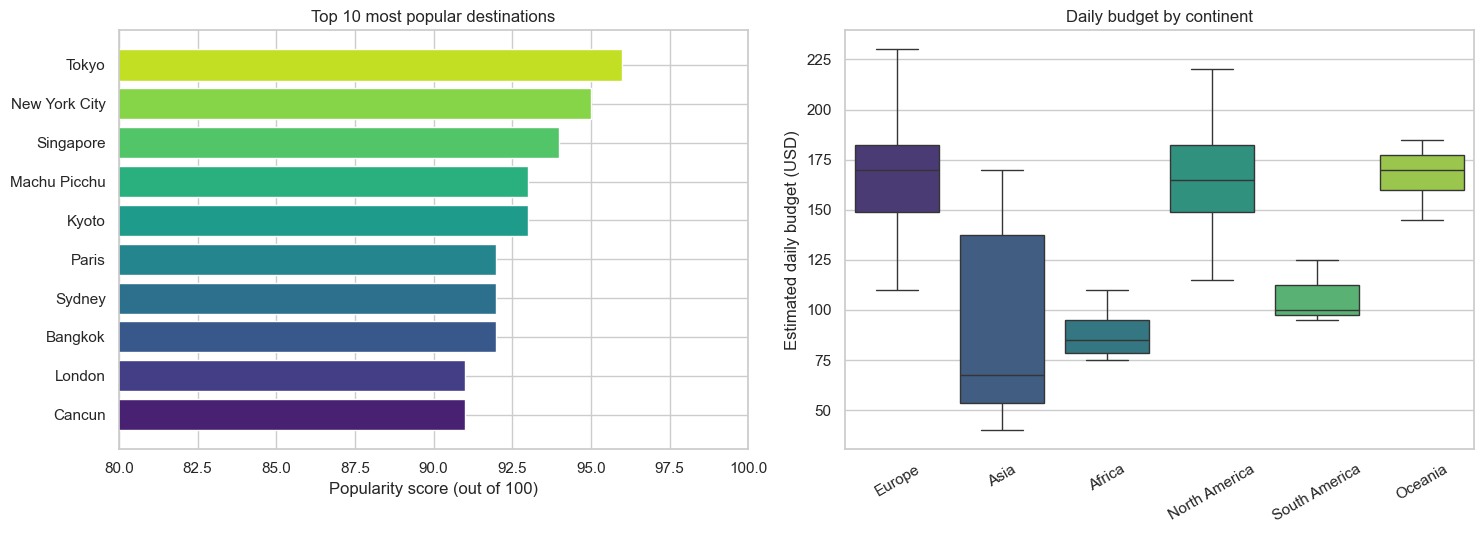

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

top = df.nlargest(10, "popularity").sort_values("popularity")
axes[0].barh(top["destination"], top["popularity"], color=sns.color_palette("viridis", 10))
axes[0].set_title("Top 10 most popular destinations")
axes[0].set_xlabel("Popularity score (out of 100)")
axes[0].set_xlim(80, 100)

sns.boxplot(data=df, x="continent", y="budget", hue="continent", legend=False, ax=axes[1])
axes[1].set_title("Daily budget by continent")
axes[1].set_xlabel(""); axes[1].set_ylabel("Estimated daily budget (USD)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

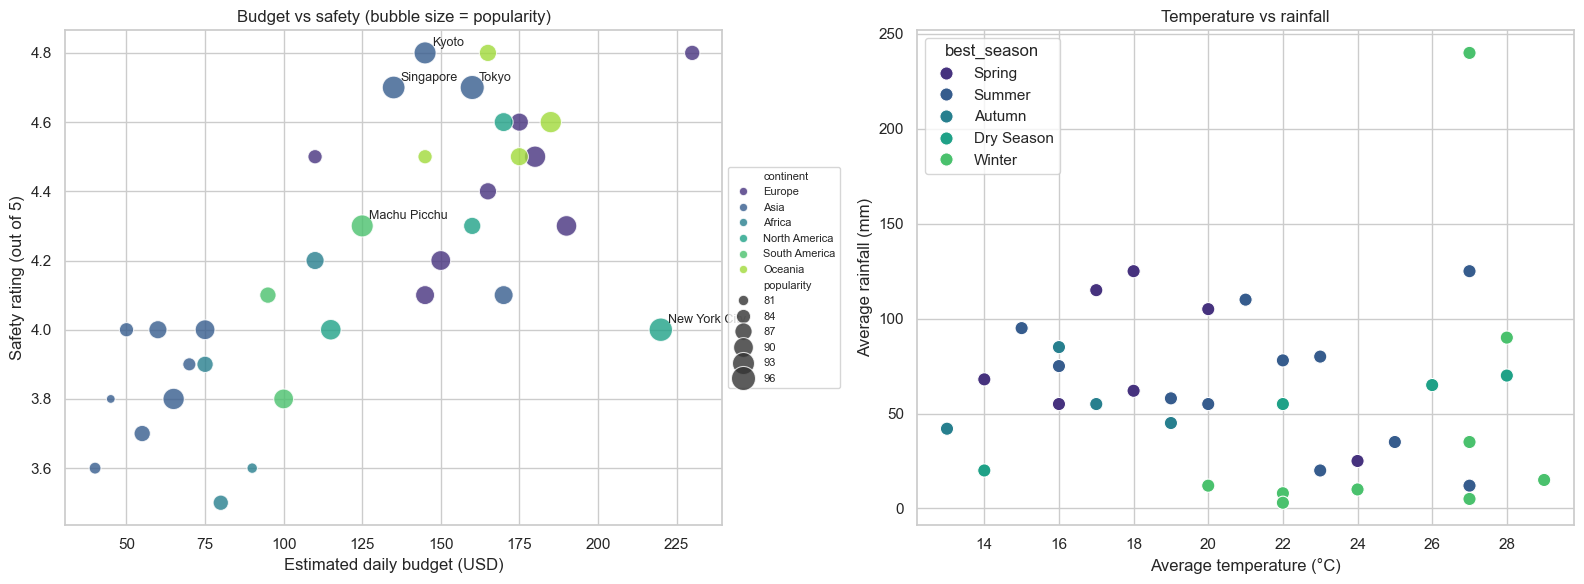

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df, x="budget", y="safety", hue="continent", size="popularity",
                sizes=(40, 300), alpha=0.8, ax=axes[0])
for _, r in df.nlargest(5, "popularity").iterrows():
    axes[0].annotate(r["destination"], (r["budget"], r["safety"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
axes[0].set_title("Budget vs safety (bubble size = popularity)")
axes[0].set_xlabel("Estimated daily budget (USD)"); axes[0].set_ylabel("Safety rating (out of 5)")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)

sns.scatterplot(data=df, x="temperature", y="rainfall", hue="best_season", s=90, ax=axes[1])
axes[1].set_title("Temperature vs rainfall")
axes[1].set_xlabel("Average temperature (°C)"); axes[1].set_ylabel("Average rainfall (mm)")
plt.tight_layout(); plt.show()

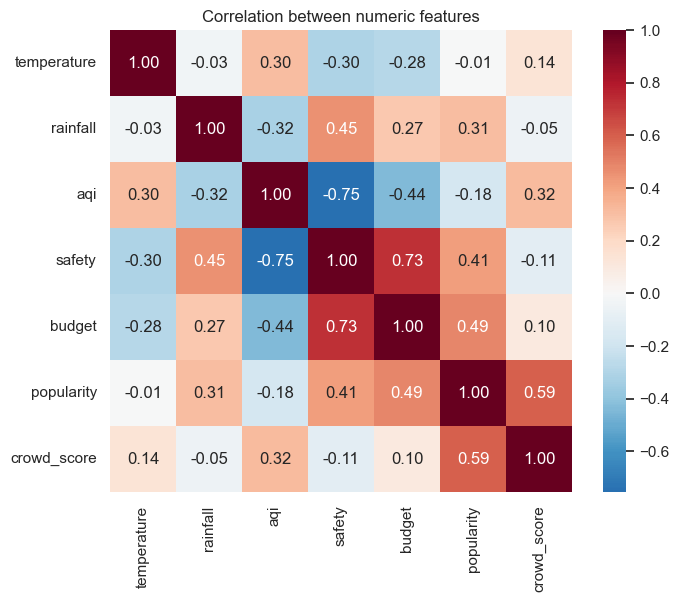

Cheapest 5:    Varanasi, Kathmandu, Manali, Jaipur, Goa
Safest 5:      Zurich, Kyoto, Queenstown, Tokyo, Singapore
Cleanest air:  Queenstown, Machu Picchu, Fiji, Zurich, Santorini


In [11]:
plt.figure(figsize=(8, 6))
corr = df[NUM_COLS + ["crowd_score"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation between numeric features")
plt.show()

print("Cheapest 5:   ", ", ".join(df.nsmallest(5, "budget")["destination"]))
print("Safest 5:     ", ", ".join(df.nlargest(5, "safety")["destination"]))
print("Cleanest air: ", ", ".join(df.nsmallest(5, "aqi")["destination"]))

## 6. Recommendation engine
### 6a. Similarity-based recommender
Each destination is described by its temperature, rainfall, air quality, safety, budget, popularity, crowd score, continent and best season. Numbers are standardised so no single feature dominates. **Cosine similarity** then finds the closest matches, and optional filters narrow them down.

In [12]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0


def apply_filters(df, seasons=None, max_budget=None, continents=None, crowd=None, min_safety=0.0):
    out = df
    if seasons:
        out = out[out["best_season"].isin(seasons)]
    if continents:
        out = out[out["continent"].isin(continents)]
    if max_budget is not None:
        out = out[out["budget"] <= max_budget]
    if crowd and crowd != "Any":
        out = out[out["crowd_level"] == crowd]
    if min_safety:
        out = out[out["safety"] >= min_safety]
    return out


def similar_destinations(df, sim, name, top_n=5, **filters):
    """Destinations most similar to `name`, optionally filtered."""
    if name not in df["destination"].values:
        raise ValueError(f"'{name}' not found. Check the spelling.")
    idx = df.index[df["destination"] == name][0]
    out = df.copy()
    out["similarity"] = ((sim[idx] + 1) / 2 * 100).round(1)   # cosine (-1..1) -> 0..100 %
    out = out.drop(index=idx)
    out = apply_filters(out, **filters)
    return out.sort_values("similarity", ascending=False).head(top_n)

### 6b. Preference-based recommender
Hard filters (season, budget, continent, crowds, minimum safety) remove destinations that do not fit. The rest are ranked by a **weighted match score from 0 to 100**. Weights (safety, affordability, air quality, popularity, temperature) can be changed to reflect what matters most to the traveller.

In [13]:
DEFAULT_WEIGHTS = {"safety": 3, "budget": 3, "air_quality": 2, "popularity": 2, "temperature": 3}
HIGHLIGHT_LABELS = {
    "safety": "High safety", "budget": "Budget friendly", "air_quality": "Clean air",
    "popularity": "Very popular", "temperature": "Matches your temperature",
}


def recommend_by_preferences(df, seasons=None, max_budget=None, continents=None, crowd=None,
                             min_safety=0.0, ideal_temp=None, weights=None, top_n=5):
    """Filter by hard constraints, then rank by a weighted match score (0-100)."""
    w = {**DEFAULT_WEIGHTS, **(weights or {})}
    parts = {
        "safety": minmax(df["safety"]),
        "budget": 1 - minmax(df["budget"]),          # cheaper = better
        "air_quality": 1 - minmax(df["aqi"]),        # lower AQI = better
        "popularity": minmax(df["popularity"]),
    }
    if ideal_temp is not None:
        gap = (df["temperature"] - ideal_temp).abs()
        parts["temperature"] = (1 - gap / 15).clip(lower=0)
    used = {k: w[k] for k in parts if w.get(k, 0) > 0} or {k: 1 for k in parts}
    total = sum(used.values())
    score = sum(parts[k] * wt for k, wt in used.items()) / total * 100

    out = apply_filters(df, seasons, max_budget, continents, crowd, min_safety).copy()
    out["match_score"] = score.loc[out.index].round(1)
    out["highlights"] = [
        " - ".join(HIGHLIGHT_LABELS[k] for k in used if parts[k].loc[i] >= 0.75)
        for i in out.index
    ]
    return out.sort_values("match_score", ascending=False).head(top_n)

## 7. Try it out

In [14]:
print("Destinations similar to Paris:")
similar_destinations(df, similarity_matrix, "Paris")[["destination", "country", "best_season", "budget", "similarity"]]

Destinations similar to Paris:


,destination,country,best_season,budget,similarity
1,Rome,Italy,Spring,150,94.2
4,London,United Kingdom,Summer,190,93.1
3,Amsterdam,Netherlands,Spring,165,89.3
32,Melbourne,Australia,Autumn,175,88.2
9,Kyoto,Japan,Spring,145,87.4


In [15]:
print("Similar to Paris, but only Summer destinations under $150/day:")
similar_destinations(df, similarity_matrix, "Paris", seasons=["Summer"], max_budget=150)[
    ["destination", "country", "best_season", "budget", "similarity"]]

Similar to Paris, but only Summer destinations under $150/day:


,destination,country,best_season,budget,similarity
2,Barcelona,Spain,Summer,145,53.7
21,Cape Town,South Africa,Summer,110,34.7
18,Manali,India,Summer,50,34.4
28,Rio de Janeiro,Brazil,Summer,100,28.5


In [16]:
print("Winter trip, budget up to $100/day, safety 3.5+, around 27°C:")
recommend_by_preferences(df, seasons=["Winter"], max_budget=100, min_safety=3.5, ideal_temp=27)[
    ["destination", "country", "temperature", "budget", "safety", "match_score", "highlights"]]

Winter trip, budget up to $100/day, safety 3.5+, around 27°C:


,destination,country,temperature,budget,safety,match_score,highlights
16,Goa,India,27,60,4.0,70.8,Budget friendly - Matches your temperature
11,Bangkok,Thailand,29,65,3.8,64.7,Budget friendly - Very popular - Matches your ...
19,Colombo,Sri Lanka,28,70,3.9,59.5,Budget friendly - Matches your temperature
15,Jaipur,India,22,55,3.7,50.0,Budget friendly
17,Varanasi,India,20,40,3.6,41.8,Budget friendly


In [17]:
print("Safe, quiet, cheap getaway anywhere (crowd level: Medium):")
recommend_by_preferences(df, crowd="Medium", min_safety=4.0, weights={"budget": 5, "safety": 4})[
    ["destination", "country", "best_season", "budget", "safety", "match_score", "highlights"]]

Safe, quiet, cheap getaway anywhere (crowd level: Medium):


,destination,country,best_season,budget,safety,match_score,highlights
33,Queenstown,New Zealand,Summer,165,4.8,66.0,High safety - Clean air
18,Manali,India,Summer,50,4.0,65.3,Budget friendly - Clean air
7,Prague,Czech Republic,Autumn,110,4.5,64.5,High safety - Clean air
21,Cape Town,South Africa,Summer,110,4.2,60.8,Clean air
25,Vancouver,Canada,Summer,170,4.6,60.0,High safety - Clean air


## 8. Interactive interface
Use the controls below and click **Find destinations**. If widgets do not appear, run `%pip install ipywidgets` once, restart the kernel and run this cell again.

In [18]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    print("ipywidgets is not installed. Run:  %pip install ipywidgets  then restart the kernel.")
else:
    style = {"description_width": "130px"}
    wide = widgets.Layout(width="420px")
    season_w = widgets.Dropdown(options=["Any"] + sorted(df["best_season"].unique()), description="Season", style=style, layout=wide)
    cont_w = widgets.Dropdown(options=["Any"] + sorted(df["continent"].unique()), description="Continent", style=style, layout=wide)
    budget_w = widgets.IntSlider(value=int(df.budget.max()), min=int(df.budget.min()), max=int(df.budget.max()), step=5,
                                 description="Max budget $/day", style=style, layout=wide)
    crowd_w = widgets.Dropdown(options=["Any"] + sorted(df["crowd_level"].unique()), description="Crowd level", style=style, layout=wide)
    safety_w = widgets.FloatSlider(value=3.5, min=0, max=5, step=0.1, description="Min safety", style=style, layout=wide)
    temp_on = widgets.Checkbox(value=False, description="I have a preferred temperature", indent=False)
    temp_w = widgets.IntSlider(value=22, min=10, max=32, description="Ideal temp (°C)", style=style, layout=wide)
    n_w = widgets.IntSlider(value=5, min=3, max=10, description="Results", style=style, layout=wide)
    button = widgets.Button(description="Find destinations", button_style="success", icon="search")
    out = widgets.Output()

    def on_click(_):
        with out:
            clear_output()
            res = recommend_by_preferences(
                df,
                seasons=None if season_w.value == "Any" else [season_w.value],
                continents=None if cont_w.value == "Any" else [cont_w.value],
                max_budget=budget_w.value, crowd=crowd_w.value, min_safety=safety_w.value,
                ideal_temp=temp_w.value if temp_on.value else None, top_n=n_w.value)
            if res.empty:
                print("No matches. Try a higher budget, lower safety minimum or a different season.")
            else:
                display(res[["destination", "country", "best_season", "temperature", "budget", "safety", "crowd_level", "match_score", "highlights"]]
                        .reset_index(drop=True).style.background_gradient(subset=["match_score"], cmap="Greens"))

    button.on_click(on_click)
    display(widgets.VBox([season_w, cont_w, budget_w, crowd_w, safety_w, temp_on, temp_w, n_w, button, out]))

## 9. Conclusion
- The cleaned dataset has **35 destinations across 6 continents** with no missing values or duplicates.
- Budget and safety are only loosely related, so there are good safe options at every price level.
- The preference-based recommender gives a transparent ranking, and the weights show what drove each result.
- The similarity recommender helps users find alternatives to places they already like.

**Possible improvements:** add more destinations, user ratings or reviews, and a month-level (not just season-level) climate.